# Weather Data Analysis – Research Questions

## Univariate Analysis (One Column)

1. What is the distribution of temperature in the dataset?
2. What is the distribution of humidity levels?
3. Which weather conditions (Summary) occur most frequently?

## Bivariate Analysis (Two Columns)

4. What is the relationship between temperature and humidity?
5. How does wind speed vary with temperature?

In [18]:
import pandas as pd

df = pd.read_csv("Climate of England _ Professional Reforms.csv")

print(df.head())
print(df.info())
print(df.columns)

  Formatted Date          Time        Summary Precip Type  Temperature (C)  \
0       4/1/2006  00:00:00.000  Partly Cloudy        rain         9.472222   
1       4/1/2006  01:00:00.000  Partly Cloudy        rain         9.355556   
2       4/1/2006  02:00:00.000  Mostly Cloudy        rain         9.377778   
3       4/1/2006  03:00:00.000  Partly Cloudy        rain         8.288889   
4       4/1/2006  04:00:00.000  Mostly Cloudy        rain         8.755556   

   Apparent Temperature (C)  Wind Speed (km/h)  Wind Bearing (degrees)  \
0                  7.388889            14.1197                   251.0   
1                  7.227778            14.2646                   259.0   
2                  9.377778             3.9284                   204.0   
3                  5.944444            14.1036                   269.0   
4                  6.977778            11.0446                   259.0   

   Visibility (km)  Pressure (millibars)  Humidity  Month  Day  Year  
0          15.8

In [19]:
# Check missing values
print(df.isnull().sum())


Formatted Date                0
Time                          0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Pressure (millibars)          0
Humidity                      0
Month                         0
Day                           0
Year                          0
dtype: int64


In [22]:
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset Shape: (96453, 14)
Columns: ['Formatted Date', 'Time', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Humidity', 'Month', 'Day', 'Year']


The dataset contains 96,453 rows and 14 columns.
It includes historical weather information.

In [23]:
print(df.dtypes)

Formatted Date                  str
Time                            str
Summary                         str
Precip Type                     str
Temperature (C)             float64
Apparent Temperature (C)    float64
Wind Speed (km/h)           float64
Wind Bearing (degrees)      float64
Visibility (km)             float64
Pressure (millibars)        float64
Humidity                    float64
Month                         int64
Day                           int64
Year                          int64
dtype: object


This shows the data type of each column.
It helps us understand the dataset structure.

In [24]:
print(df.describe())

       Temperature (C)  Apparent Temperature (C)  Wind Speed (km/h)  \
count     96453.000000              96453.000000       96453.000000   
mean         11.932678                 10.855029          10.810640   
std           9.551546                 10.696847           6.913571   
min         -21.822222                -27.716667           0.000000   
25%           4.688889                  2.311111           5.828200   
50%          12.000000                 12.000000           9.965900   
75%          18.838889                 18.838889          14.135800   
max          39.905556                 39.344444          63.852600   

       Wind Bearing (degrees)  Visibility (km)  Pressure (millibars)  \
count            96453.000000     96453.000000          96453.000000   
mean               187.509232        10.347325           1003.235956   
std                107.383428         4.192123            116.969906   
min                  0.000000         0.000000              0.000000   


This provides statistical information such as mean, minimum, maximum and standard deviation.

In [25]:
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'])

print("First Date:", df['Formatted Date'].min())
print("Last Date:", df['Formatted Date'].max())

First Date: 2006-01-01 00:00:00
Last Date: 2016-12-31 00:00:00


The date column was converted into datetime format.
This helps us analyze weather trends over time.

In [26]:
print(df.columns.tolist())

['Formatted Date', 'Time', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Humidity', 'Month', 'Day', 'Year']


The dataset does not contain a separate country or location column.
Therefore, country-wise comparison is not possible.

In [28]:
df = df[['Formatted Date', 'Temperature (C)', 'Humidity',
         'Summary', 'Wind Speed (km/h)']]

print(df.head())
print(df.shape)

  Formatted Date  Temperature (C)  Humidity        Summary  Wind Speed (km/h)
0     2006-04-01         9.472222      0.89  Partly Cloudy            14.1197
1     2006-04-01         9.355556      0.86  Partly Cloudy            14.2646
2     2006-04-01         9.377778      0.89  Mostly Cloudy             3.9284
3     2006-04-01         8.288889      0.83  Partly Cloudy            14.1036
4     2006-04-01         8.755556      0.83  Mostly Cloudy            11.0446
(96453, 5)


Only the required columns were selected for analysis.
These columns will help answer the five research questions.

In [30]:
raw_df = pd.read_csv("Climate of England _ Professional Reforms.csv")

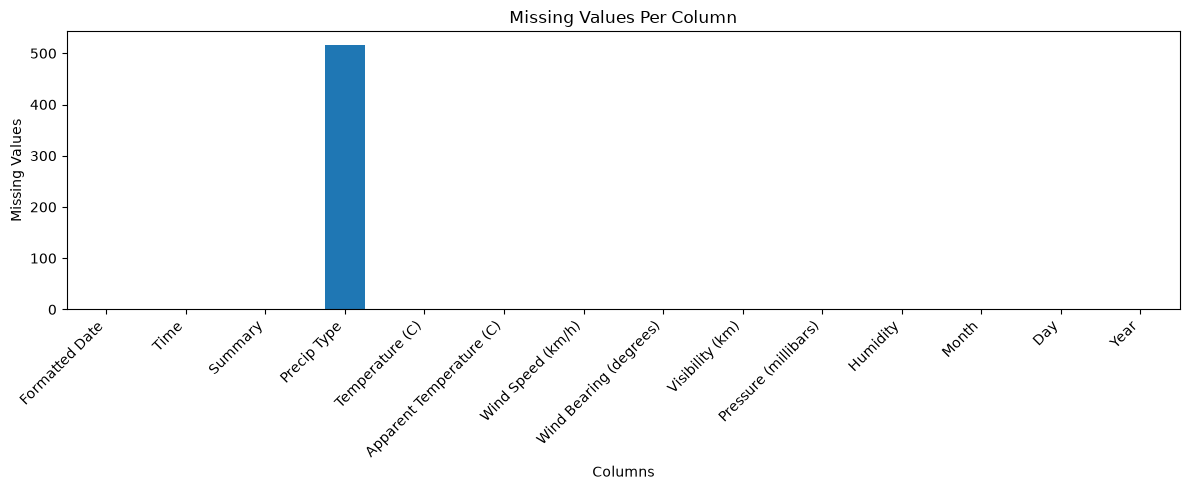

In [31]:
import matplotlib.pyplot as plt

missing = raw_df.isnull().sum()

missing.plot(kind='bar', figsize=(12, 5))

plt.title("Missing Values Per Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [32]:
raw_df['Precip Type'] = raw_df['Precip Type'].ffill()

print(raw_df.isnull().sum())

Formatted Date              0
Time                        0
Summary                     0
Precip Type                 0
Temperature (C)             0
Apparent Temperature (C)    0
Wind Speed (km/h)           0
Wind Bearing (degrees)      0
Visibility (km)             0
Pressure (millibars)        0
Humidity                    0
Month                       0
Day                         0
Year                        0
dtype: int64


Missing values in Precip Type were filled using the previous value.
All other columns had no missing values.

In [33]:
print("Duplicate Rows:", raw_df.duplicated().sum())

Duplicate Rows: 24


In [35]:
raw_df = raw_df.drop_duplicates()

print("Shape after removing duplicates:", raw_df.shape)
print("Remaining duplicates:", raw_df.duplicated().sum())

Shape after removing duplicates: (96429, 14)
Remaining duplicates: 0


24 duplicate rows were found and removed.
This prevents repeated records from affecting the analysis.

In [34]:
print("Duplicate Dates:", raw_df['Formatted Date'].duplicated().sum())

Duplicate Dates: 92435


In [36]:
print("Duplicate Date and Time:",
      raw_df.duplicated(subset=['Formatted Date', 'Time']).sum())

Duplicate Date and Time: 11


The dataset contains hourly weather records.
Therefore, duplicate dates alone do not mean duplicate records.
Date and time must be checked together.

In [37]:
raw_df = raw_df.drop_duplicates(
    subset=['Formatted Date', 'Time']
)

print("Remaining duplicate Date and Time:",
      raw_df.duplicated(
          subset=['Formatted Date', 'Time']
      ).sum())

print("Final Shape:", raw_df.shape)

Remaining duplicate Date and Time: 0
Final Shape: (96418, 14)


11 repeated date and time records were removed.
After removing them, no duplicate date and time records remain.
Final dataset contains 96,418 rows and 14 columns.

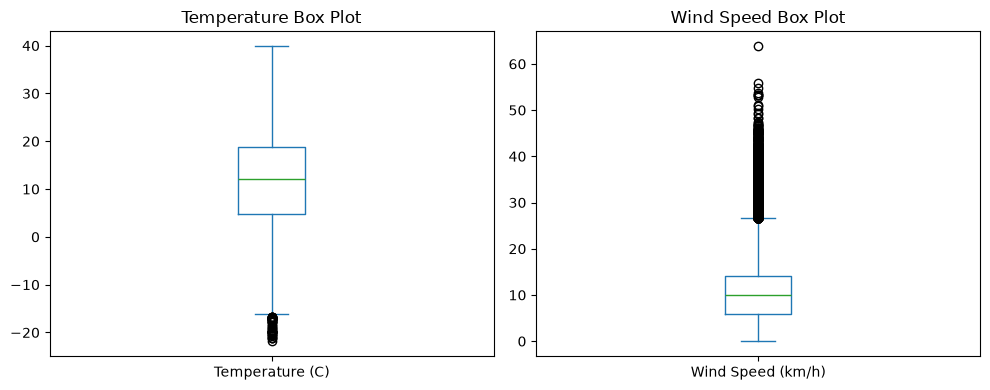

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
raw_df['Temperature (C)'].plot(kind='box')
plt.title('Temperature Box Plot')

plt.subplot(1, 2, 2)
raw_df['Wind Speed (km/h)'].plot(kind='box')
plt.title('Wind Speed Box Plot')

plt.tight_layout()
plt.show()

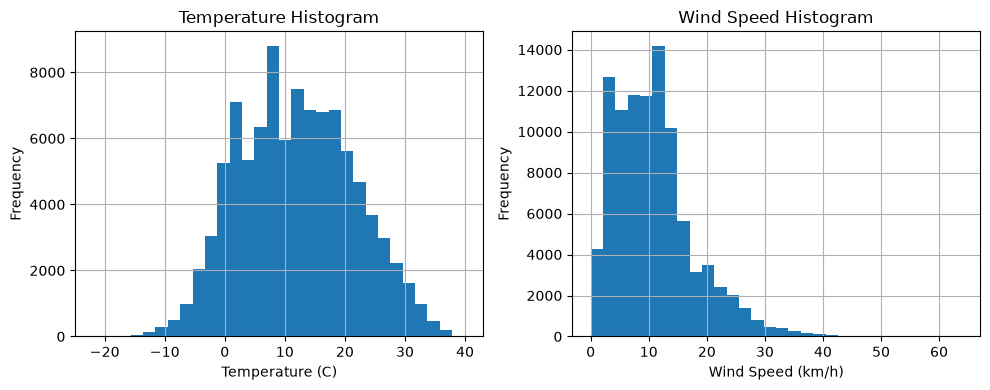

In [39]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
raw_df['Temperature (C)'].hist(bins=30)
plt.title('Temperature Histogram')
plt.xlabel('Temperature (C)')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
raw_df['Wind Speed (km/h)'].hist(bins=30)
plt.title('Wind Speed Histogram')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Q1: What is the distribution of temperature in the dataset?

**Graph:** Temperature Distribution Histogram

**Answer:**

The average temperature is 11.93°C and the median is 12°C. The minimum temperature is -21.82°C and the maximum is 39.91°C. Most temperatures are around 12°C.

---


In [40]:
columns = ['Temperature (C)', 'Wind Speed (km/h)']

for col in columns:
    Q1 = raw_df[col].quantile(0.25)
    Q3 = raw_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = raw_df[
        (raw_df[col] < lower) | (raw_df[col] > upper)
    ]

    print(col)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Outliers:", len(outliers))
    print("--------------------")

Temperature (C)
Lower Limit: -16.5500000025
Upper Limit: 40.0722222255
Outliers: 44
--------------------
Wind Speed (km/h)
Lower Limit: -6.633200000000001
Upper Limit: 26.5972
Outliers: 3019
--------------------


In [41]:
print("Temperature Outliers:")
print(raw_df[
    (raw_df['Temperature (C)'] < -16.55) |
    (raw_df['Temperature (C)'] > 40.07)
]['Temperature (C)'].describe())

print("\nWind Speed Outliers:")
print(raw_df[
    raw_df['Wind Speed (km/h)'] > 26.59
]['Wind Speed (km/h)'].describe())

Temperature Outliers:
count    44.000000
mean    -18.652652
std       1.581676
min     -21.822222
25%     -20.000000
50%     -18.458333
75%     -17.222222
max     -16.666667
Name: Temperature (C), dtype: float64

Wind Speed Outliers:
count    3027.000000
mean       31.497302
std         4.538707
min        26.597200
25%        27.933500
50%        30.284100
75%        33.810000
max        63.852600
Name: Wind Speed (km/h), dtype: float64


Outlier Analysis:

IQR method was applied to Temperature and Wind Speed.

Temperature had 44 outliers. These very low temperatures may represent real cold weather conditions.

Wind Speed had 3,019 outliers according to the IQR count. These high wind speeds may represent real windy weather conditions.

No outliers were removed because they may be genuine weather observations.

In [42]:
print(raw_df['Wind Speed (km/h)'].quantile(0.75))
print(raw_df['Wind Speed (km/h)'].quantile(0.75) +
      1.5 * (raw_df['Wind Speed (km/h)'].quantile(0.75) -
             raw_df['Wind Speed (km/h)'].quantile(0.25)))

14.1358
26.5972


In [43]:
upper = 26.5972

print("Wind Speed Outliers:",
      (raw_df['Wind Speed (km/h)'] > upper).sum())

Wind Speed Outliers: 3019


The IQR method found 44 temperature outliers and 3,019 wind speed outliers. These extreme values may represent real weather conditions, so they were not removed.

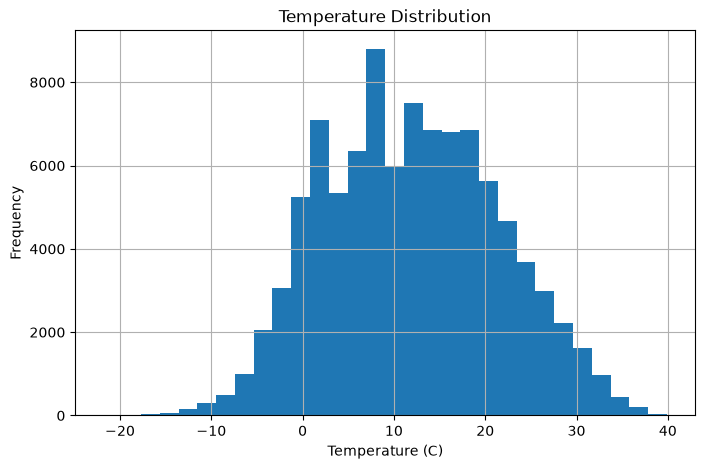

Mean: 11.930326979064375
Median: 12.0
Minimum: -21.82222222
Maximum: 39.90555556


In [44]:
plt.figure(figsize=(8, 5))

raw_df['Temperature (C)'].hist(bins=30)

plt.title('Temperature Distribution')
plt.xlabel('Temperature (C)')
plt.ylabel('Frequency')
plt.show()

print("Mean:", raw_df['Temperature (C)'].mean())
print("Median:", raw_df['Temperature (C)'].median())
print("Minimum:", raw_df['Temperature (C)'].min())
print("Maximum:", raw_df['Temperature (C)'].max())

Temperature Analysis:

The average temperature is 11.93°C and the median is 12°C.
The minimum temperature is -21.82°C and the maximum is 39.91°C.

The typical temperature is around 12°C.
The temperature has a wide spread, ranging from -21.82°C to 39.91°C.

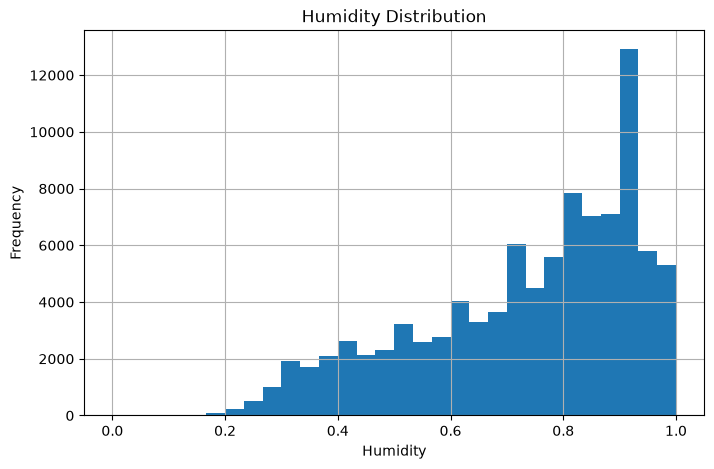

Mean: 0.7348809350951068
Median: 0.78
Minimum: 0.0
Maximum: 1.0


In [45]:
plt.figure(figsize=(8, 5))

raw_df['Humidity'].hist(bins=30)

plt.title('Humidity Distribution')
plt.xlabel('Humidity')
plt.ylabel('Frequency')
plt.show()

print("Mean:", raw_df['Humidity'].mean())
print("Median:", raw_df['Humidity'].median())
print("Minimum:", raw_df['Humidity'].min())
print("Maximum:", raw_df['Humidity'].max())



---

### Q2: What is the distribution of humidity levels?

**Graph:** Humidity Distribution Histogram

**Answer:**

The average humidity is 0.735 and the median is 0.78. The minimum humidity is 0 and the maximum is 1. Most humidity values are around 0.78.

Humidity Analysis:

The average humidity is 0.735 and the median is 0.78.
The minimum humidity is 0 and the maximum is 1.

The typical humidity is around 0.78.
Humidity values range from 0 to 1.

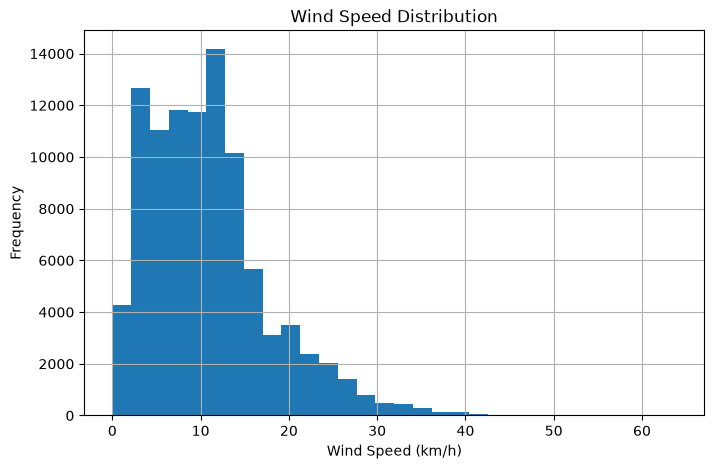

Mean: 10.812895455205458
Median: 9.9659
Minimum: 0.0
Maximum: 63.8526


In [46]:
plt.figure(figsize=(8, 5))

raw_df['Wind Speed (km/h)'].hist(bins=30)

plt.title('Wind Speed Distribution')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Frequency')
plt.show()

print("Mean:", raw_df['Wind Speed (km/h)'].mean())
print("Median:", raw_df['Wind Speed (km/h)'].median())
print("Minimum:", raw_df['Wind Speed (km/h)'].min())
print("Maximum:", raw_df['Wind Speed (km/h)'].max())

Wind Speed Analysis:

The average wind speed is 10.81 km/h and the median is 9.97 km/h.
The minimum wind speed is 0 km/h and the maximum is 63.85 km/h.

The typical wind speed is around 10 km/h.
Wind speed values range from 0 to 63.85 km/h.

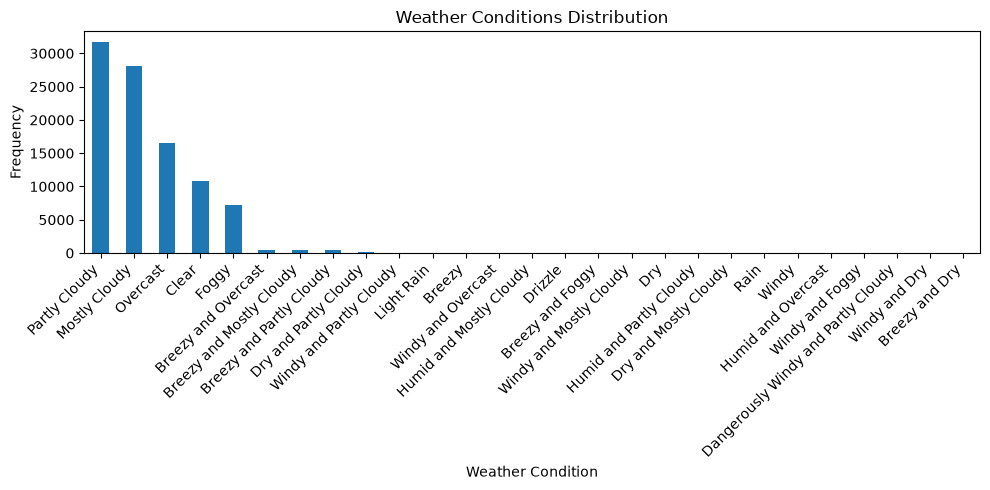

In [47]:
plt.figure(figsize=(10, 5))

raw_df['Summary'].value_counts().plot(kind='bar')

plt.title('Weather Conditions Distribution')
plt.xlabel('Weather Condition')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

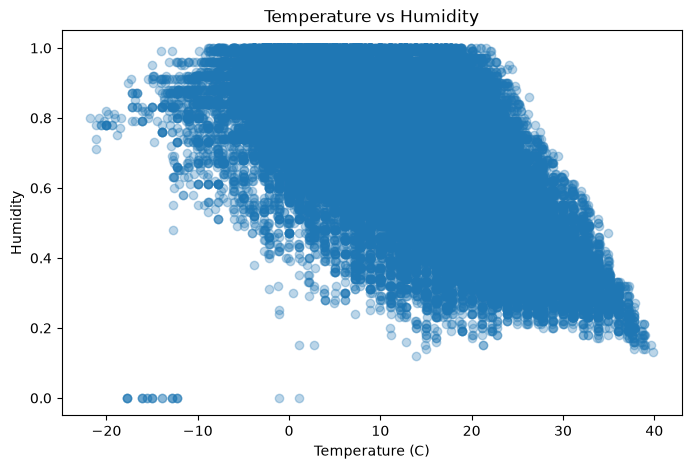

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(
    raw_df['Temperature (C)'],
    raw_df['Humidity'],
    alpha=0.3
)

plt.title('Temperature vs Humidity')
plt.xlabel('Temperature (C)')
plt.ylabel('Humidity')

plt.show()

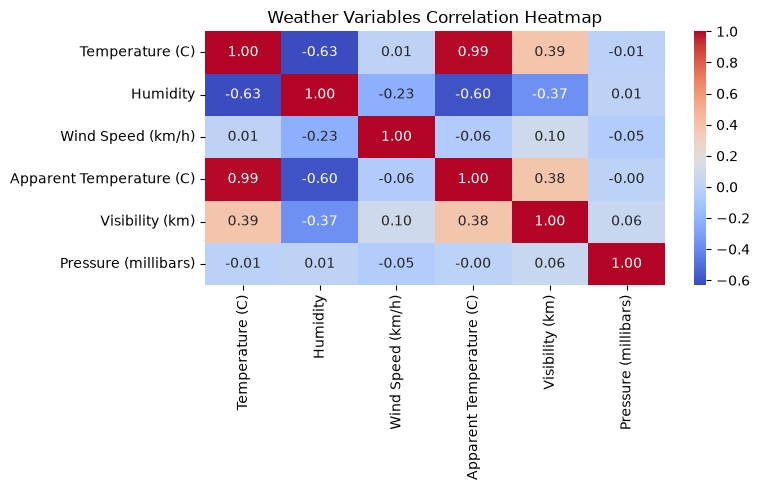

In [49]:
import seaborn as sns

corr = raw_df[['Temperature (C)', 'Humidity',
               'Wind Speed (km/h)',
               'Apparent Temperature (C)',
               'Visibility (km)',
               'Pressure (millibars)']].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Weather Variables Correlation Heatmap')
plt.tight_layout()
plt.show()

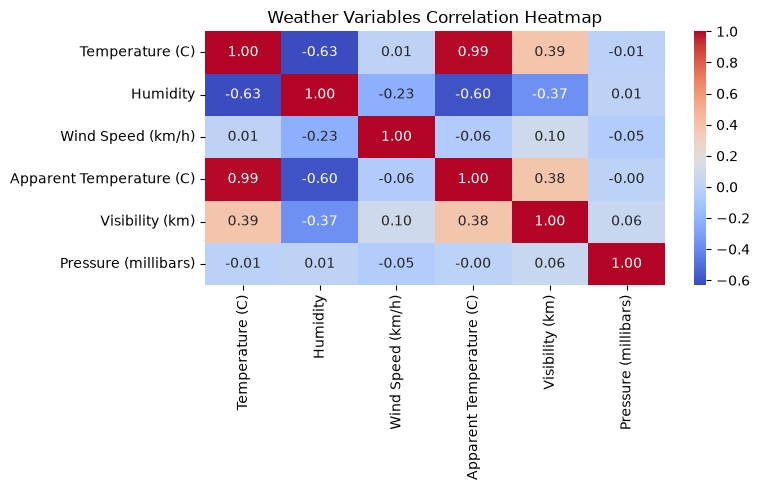

In [50]:
import seaborn as sns

corr = raw_df[['Temperature (C)', 'Humidity',
               'Wind Speed (km/h)',
               'Apparent Temperature (C)',
               'Visibility (km)',
               'Pressure (millibars)']].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Weather Variables Correlation Heatmap')
plt.tight_layout()
plt.show()

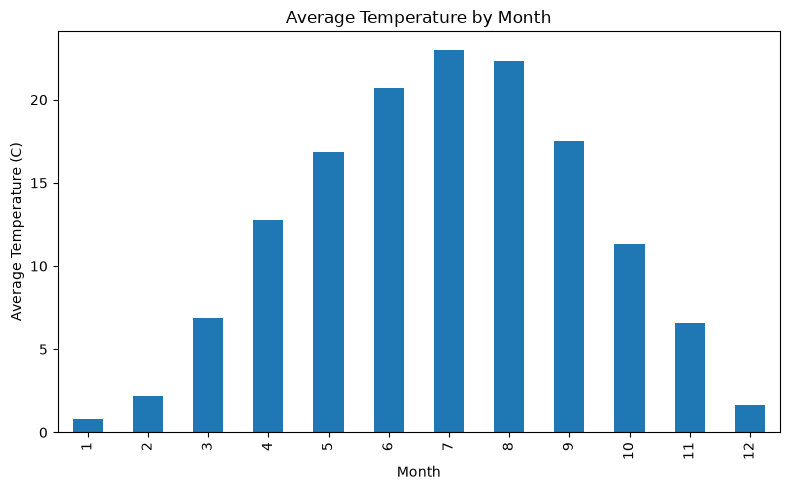

In [51]:
monthly_temp = raw_df.groupby('Month')['Temperature (C)'].mean()

plt.figure(figsize=(8, 5))
monthly_temp.plot(kind='bar')
plt.title('Average Temperature by Month')
plt.xlabel('Month')
plt.ylabel('Average Temperature (C)')
plt.tight_layout()
plt.show()

In [52]:
print(raw_df['Summary'].value_counts().head())

Summary
Partly Cloudy    31723
Mostly Cloudy    28093
Overcast         16595
Clear            10872
Foggy             7144
Name: count, dtype: int64


**Q3: Which weather conditions occur most frequently?**

Partly Cloudy is the most frequent weather condition, occurring 31,723 times. Mostly Cloudy comes second with 28,093 records, followed by Overcast with 16,595 records.

In [53]:
print("Temperature and Humidity Correlation:")
print(raw_df['Temperature (C)'].corr(raw_df['Humidity']))

Temperature and Humidity Correlation:
-0.6323225896399617


**Q4: What is the relationship between temperature and humidity?**

The correlation between temperature and humidity is -0.63. This shows a moderate negative relationship. As temperature increases, humidity generally tends to decrease.

In [54]:
print("Temperature and Wind Speed Correlation:")
print(raw_df['Temperature (C)'].corr(raw_df['Wind Speed (km/h)']))

Temperature and Wind Speed Correlation:
0.009275133543498466


**Q5: How does wind speed vary with temperature?**

The correlation between temperature and wind speed is 0.009. This shows almost no linear relationship between them. Temperature changes do not show a clear pattern with wind speed in this dataset.